# Backtest 4 · Daily (D1) and 4-hour (H4) walk-forward

Candles close at the 17:00 New York rollover, like MT5 brokers. Costs: Vantage spreads (median per candle, 2019+; each cross's median before), commission 0.003% per side, swap = current Vantage rate on the more expensive side, 7 nights per 5 trading days.

TRAIN 2010 – 2018 chooses parameters and crosses; TEST 2019 → latest is run untouched.

1. The 8 original crosses, D1 and H4.
2. All 23 crosses on D1, with worst-side swap and on a swap-free account.

In [1]:
import sys
sys.path.insert(0, "../src")   # shared code lives in src/; data in ../data (see README)
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200)

In [2]:
%run ../src/tf_strategy.py --tf D1 H4


D1, 8 crosses, swap: worst: 4,427 candles, 2010-01-04 -> 2026-10-16   train < 2019-01-01 <= test
swap charged per night (% of position, worst side): AUDNZD 0.0072  EURGBP 0.0075  EURCHF 0.0122  AUDCAD 0.0090  NZDCAD 0.0039  CADCHF 0.0107  EURNOK 0.0082  EURSEK 0.0042



Top 8 by TRAIN Sharpe (test columns shown for transparency, never used to choose):
 window  entry  exit  max_hl  crosses  train trades  TRAIN Sharpe  TRAIN %/yr  test Sharpe  test %/yr
    120    2.5   0.5      10        6           112          0.67        2.96         0.15       0.72
    120    2.5   0.5      20        5           117          0.64        3.14        -0.06      -0.31
    120    2.0   0.5      10        6           193          0.63        3.35         0.18       1.10
    120    2.5   0.5       5        2            12          0.57        0.47        -0.39      -0.50
    120    2.0   0.0      10        6           182          0.55        3.33         0.16       1.05
    120    2.5   0.0      10        6           105          0.51        2.61        -0.00      -0.02
    120    2.0   0.5      20        5           211          0.49        3.05         0.02       0.09
    250    2.5   0.5      10        3            13          0.44        0.64        -0.72      -1.2

    risk x1: 381 attempts | unfinished 100%
    risk x2: 385 attempts | unfinished 74% | fail: daily loss 12% | pass 8% | fail: max loss 6%


    risk x4: 397 attempts | pass 36% | unfinished 34% | fail: daily loss 21% | fail: max loss 10%

Robustness across all 54 combinations in TEST: positive 7, median test Sharpe -0.31, corr(train, test Sharpe) 0.36


spreads x2 on the chosen setup, TEST Sharpe: 0.11



H4, 8 crosses, swap: worst: 26,088 candles, 2010-01-04 -> 2026-10-16   train < 2019-01-01 <= test
swap charged per night (% of position, worst side): AUDNZD 0.0072  EURGBP 0.0075  EURCHF 0.0122  AUDCAD 0.0090  NZDCAD 0.0039  CADCHF 0.0107  EURNOK 0.0082  EURSEK 0.0042



Top 8 by TRAIN Sharpe (test columns shown for transparency, never used to choose):
 window  entry  exit  max_hl  crosses  train trades  TRAIN Sharpe  TRAIN %/yr  test Sharpe  test %/yr
    360    2.5   0.5      12        3            20          0.55        0.50        -0.35      -0.50
    360    1.5   0.5      12        6           201          0.50        1.10        -0.06      -0.16
    720    2.0   0.0      12        1             1          0.49        0.07          NaN       0.00
    720    1.5   0.5      30        5           156          0.44        1.29         0.33       1.19
    720    2.5   0.0      60        6            63          0.44        1.74         0.70       2.95
    360    2.0   0.5      12        6           106          0.41        0.74         0.17       0.38
    720    2.5   0.0      30        7            35          0.41        0.86         0.22       0.57
    360    1.5   0.0      12        4           121          0.41        0.90        -0.16      -0.4

    risk x1: 381 attempts | unfinished 100%


    risk x2: 381 attempts | unfinished 100%


    risk x4: 381 attempts | unfinished 93% | fail: daily loss 6% | pass 0%

Robustness across all 54 combinations in TEST: positive 18, median test Sharpe -0.19, corr(train, test Sharpe) 0.43


spreads x2 on the chosen setup, TEST Sharpe: -0.40


In [3]:
%run ../src/tf_strategy.py --tf D1 --universe all --swap worst


D1, 23 crosses, swap: worst: 4,427 candles, 2010-01-04 -> 2026-10-16   train < 2019-01-01 <= test
swap charged per night (% of position, worst side): AUDNZD 0.0072  EURGBP 0.0075  EURCHF 0.0122  AUDCAD 0.0090  NZDCAD 0.0039  CADCHF 0.0107  EURNOK 0.0082  EURSEK 0.0042  EURJPY 0.0053  GBPJPY 0.0093  AUDJPY 0.0105  NZDJPY 0.0060  CADJPY 0.0045  CHFJPY 0.0050  EURAUD 0.0081  EURNZD 0.0024  EURCAD 0.0031  GBPAUD 0.0056  GBPNZD 0.0061  GBPCAD 0.0078  GBPCHF 0.0178  AUDCHF 0.0173  NZDCHF 0.0126



Top 8 by TRAIN Sharpe (test columns shown for transparency, never used to choose):
 window  entry  exit  max_hl  crosses  train trades  TRAIN Sharpe  TRAIN %/yr  test Sharpe  test %/yr
    120    2.5   0.5       5       10            80          0.88        2.43        -0.00      -0.00
    120    2.5   0.5      10       13           249          0.86        6.35         0.25       1.92
    120    2.0   0.5       5       14           174          0.84        3.28        -0.34      -1.49
    120    2.5   0.5      20       12           287          0.81        7.13        -0.20      -1.69
    120    2.0   0.0       5       13           157          0.79        3.52        -0.26      -1.34
    120    2.5   0.0       5       12            91          0.74        2.52         0.01       0.04
    250    2.5   0.0      10       12            35          0.74        2.12        -0.28      -1.14
    120    1.5   0.5       5       13           257          0.70        3.27        -0.43      -2.3

    risk x2: 381 attempts | unfinished 99% | fail: max loss 1%
    risk x4: 387 attempts | unfinished 71% | pass 11% | fail: daily loss 10% | fail: max loss 8%

Robustness across all 54 combinations in TEST: positive 13, median test Sharpe -0.22, corr(train, test Sharpe) 0.52


spreads x2 on the chosen setup, TEST Sharpe: -0.04


In [4]:
%run ../src/tf_strategy.py --tf D1 --universe all --swap none


D1, 23 crosses, swap: none: 4,427 candles, 2010-01-04 -> 2026-10-16   train < 2019-01-01 <= test
swap charged per night (% of position, worst side): AUDNZD 0.0000  EURGBP 0.0000  EURCHF 0.0000  AUDCAD 0.0000  NZDCAD 0.0000  CADCHF 0.0000  EURNOK 0.0000  EURSEK 0.0000  EURJPY 0.0000  GBPJPY 0.0000  AUDJPY 0.0000  NZDJPY 0.0000  CADJPY 0.0000  CHFJPY 0.0000  EURAUD 0.0000  EURNZD 0.0000  EURCAD 0.0000  GBPAUD 0.0000  GBPNZD 0.0000  GBPCAD 0.0000  GBPCHF 0.0000  AUDCHF 0.0000  NZDCHF 0.0000



Top 8 by TRAIN Sharpe (test columns shown for transparency, never used to choose):
 window  entry  exit  max_hl  crosses  train trades  TRAIN Sharpe  TRAIN %/yr  test Sharpe  test %/yr
    120    2.5   0.5      10       13           249          1.10        8.11         0.58       4.43
    120    2.5   0.5      20       12           287          1.09        9.65         0.20       1.65
    120    2.0   0.5       5       14           174          1.07        4.18        -0.06      -0.27
    120    2.5   0.5       5       10            80          1.03        2.83         0.19       0.54
    120    2.0   0.0       5       13           157          0.99        4.41        -0.02      -0.09
    120    2.5   0.0      10       14           252          0.95        8.44         0.48       4.32
    120    1.5   0.5       5       13           257          0.94        4.40        -0.14      -0.79
    120    2.0   0.0      10       14           425          0.93       11.70         0.52       6.0

    risk x2: 398 attempts | pass 47% | unfinished 33% | fail: daily loss 11% | fail: max loss 10%
    risk x4: 399 attempts | pass 53% | fail: daily loss 37% | fail: max loss 7% | unfinished 3%

Robustness across all 54 combinations in TEST: positive 41, median test Sharpe 0.36, corr(train, test Sharpe) 0.21


spreads x2 on the chosen setup, TEST Sharpe: 0.54


### Equity of the chosen D1 setup (23-cross universe, swap-free)
Window 120 days, entry |s| ≥ 2.5, exit 0.5, max half-life 10 days; 13 crosses kept on TRAIN.

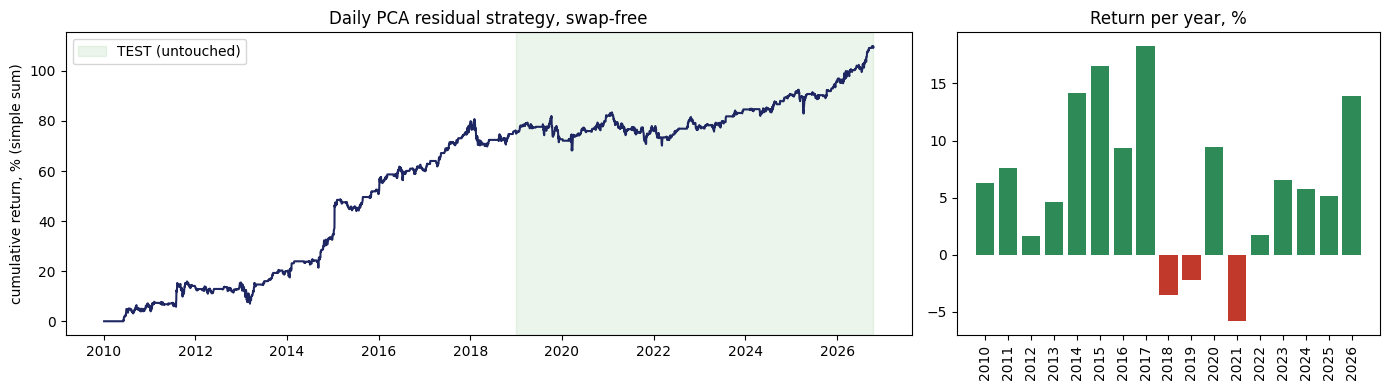

entry,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
trades,16.0,32.0,14.0,37.0,34.0,29.0,31.0,32.0,24.0,25.0,33.0,34.0,33.0,27.0,22.0,37.0,28.0
win_pct,56.2,62.5,50.0,62.2,79.4,69.0,64.5,78.1,50.0,56.0,60.6,55.9,63.6,74.1,72.7,70.3,78.6


In [5]:
from forex_analysis import fx_trades
tr, ret = fx_trades()
split = pd.Timestamp("2019-01-01", tz="UTC")
fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [2, 1]})
eq = ret.cumsum() * 100
axes[0].plot(eq.index, eq, color="#1E2761")
axes[0].axvspan(split, eq.index[-1], color="green", alpha=0.08, label="TEST (untouched)")
axes[0].set_ylabel("cumulative return, % (simple sum)")
axes[0].set_title("Daily PCA residual strategy, swap-free")
axes[0].legend()
yr = ret.groupby(ret.index.year).sum() * 100
axes[1].bar(yr.index.astype(str), yr, color=["#2E8B57" if v > 0 else "#C0392B" for v in yr])
axes[1].tick_params(axis="x", rotation=90)
axes[1].set_title("Return per year, %")
plt.tight_layout()
plt.show()
tr.groupby(tr["entry"].dt.year).agg(trades=("net", "size"), win_pct=("net", lambda x: (x > 0).mean() * 100)).round(1).T

**Result:** daily candles are the only timeframe that holds up. With 23 crosses on a swap-free account the TEST Sharpe is 0.58 (4.4%/yr, 239 trades); with worst-side swap it is about flat. H4 fails after costs.